# Week 5: Predictive analytics of Kerala surface water quality
**ESCI 620 | Project Assignment 3**

**Research question:** How well can pH, district and seasonal timing estimate dissolved oxygen (DO) in later observations from Kerala's monitoring network?

DO is continuous, so I chose multiple linear regression. Week 4 showed a weak overall DO-pH relationship and nearly zero within-station correlation. BOD is absent, so I cannot test my original BOD question. This model estimates DO conditional on available pH, not an unconditional future forecast. The chronological holdout tests later observations. The course guidance recommends separating training and testing and using appropriate metrics (Scikit-learn, n.d.-a, n.d.-b).

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import sklearn
import sys

RAW = Path('KERALA_CPCB_WATER_QUALITY_RAW_20261101.csv')
raw = pd.read_csv(RAW)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)
print('Raw shape:', raw.shape)
print('SHA-256:', hashlib.sha256(RAW.read_bytes()).hexdigest())

Python: 3.13.5 | pandas: 2.2.3 | sklearn: 1.8.0
Raw shape: (3572, 52)
SHA-256: 980f1b2adaf209ebca407c7bc8d5e29cb076f58bcc3abf534da8f0d1dcb55cb5


## 1. Clean the modeling dataset
The Week 3 cleaned CSV is not available. I reproduce its relevant rules from the unchanged source (Central Pollution Control Board, n.d.): parse dates strictly, normalize station and district labels, convert nonnumeric readings to missing, retain outliers, and do not impute. The export contains all source rows but only the fields needed for this analysis; it is not a reconstruction of the complete 38-column Week 3 export. Missing target or predictor values are excluded only from model fitting and evaluation.

In [2]:
d = pd.DataFrame({'source_row_id': raw['SlNo'],
                  'station': raw['Station'].str.strip().str.replace(r'\s+', ' ', regex=True).str.upper(),
                  'district': raw['District'].str.strip().str.replace(r'\s+', ' ', regex=True).str.title(),
                  'observation_date': pd.to_datetime(raw['Data Acquisition Time'], format='%d-%m-%Y %H:%M').dt.normalize(),
                  'latitude': raw['Latitude'], 'longitude': raw['Longitude'],
                  'ph': pd.to_numeric(raw['Potential of Hydrogen (pH)'], errors='coerce'),
                  'do_mg_L': pd.to_numeric(raw['Dissolved oxygen (mg/L)'], errors='coerce')})
d['do_status'] = np.where(raw['Dissolved oxygen (mg/L)'].isna(), 'missing', np.where(d.do_mg_L.isna(), 'nonnumeric', 'numeric'))
d['ph_status'] = np.where(d.ph.isna(), 'missing', 'numeric')
d['month_sin'] = np.sin(2*np.pi*(d.observation_date.dt.month-1)/12)
d['month_cos'] = np.cos(2*np.pi*(d.observation_date.dt.month-1)/12)
d['eligible'] = d[['ph','do_mg_L','district']].notna().all(axis=1)
assert len(d)==3572 and d.source_row_id.is_unique
assert d.do_mg_L.notna().sum()==3341 and d.ph.notna().sum()==3565
print(d[['ph','do_mg_L']].describe().round(3))
print('Eligible:', d.eligible.sum(), '| excluded from fit:', (~d.eligible).sum())
print('Stations with numeric DO:', d.loc[d.do_mg_L.notna(),'station'].nunique())

             ph   do_mg_L
count  3565.000  3341.000
mean      6.984     6.226
std       0.547     1.603
min       2.000     0.200
25%       6.600     5.600
50%       6.900     6.600
75%       7.400     7.300
max       8.800     9.900
Eligible: 3341 | excluded from fit: 231
Stations with numeric DO: 96


## 2. Preprocessing and chronological train/test split
I reserve approximately the last 20% of complete observations by date, keeping observations from the same day together. Unlike a random row split, this checks performance on later dates. District is one-hot encoded inside a pipeline fitted only on training data. Month is represented by sine and cosine to preserve the December-January connection. Scaling is unnecessary for ordinary least squares because there is no distance-based calculation or penalty. No target-derived features are used.

In [3]:
m = d.loc[d.eligible].sort_values(['observation_date','source_row_id']).copy()
cutoff = m.iloc[int(0.8*len(m))].observation_date
train = m[m.observation_date < cutoff].copy()
test = m[m.observation_date >= cutoff].copy()
assert train.observation_date.max() < test.observation_date.min()
assert set(train.source_row_id).isdisjoint(test.source_row_id)
d['split'] = 'excluded'
d.loc[train.index,'split'] = 'train'
d.loc[test.index,'split'] = 'test'
d.to_csv('Boubacar_ProjectAssignment3.csv', index=False)
features = ['ph','month_sin','month_cos','district']
X_train, y_train = train[features], train.do_mg_L
X_test, y_test = test[features], test.do_mg_L
print('Cutoff:', cutoff.date())
for label, frame in [('Train',train),('Test',test)]:
    print(label, len(frame), f'({len(frame)/len(m):.1%})', frame.observation_date.min().date(), frame.observation_date.max().date(), 'stations:', frame.station.nunique())
print('Test stations not present in training:', len(set(test.station)-set(train.station)))
print('Unseen test districts:', sorted(set(test.district)-set(train.district)))

Cutoff: 2020-05-15
Train 2670 (79.9%) 2018-01-01 2020-05-14 stations: 96
Test 671 (20.1%) 2020-05-15 2020-12-24 stations: 96
Test stations not present in training: 0
Unseen test districts: []


## 3. Fit and validate
Compare regression with a baseline that always predicts the training mean. R² describes improvement relative to a constant test-mean prediction; RMSE penalizes large errors, while MAE gives average absolute error in mg/L. The baseline comparison is recommended in the supplied metrics reading (Scikit-learn, n.d.-b).

In [4]:
preprocess = ColumnTransformer([('district', OneHotEncoder(handle_unknown='ignore', drop='first'), ['district']), ('numeric', 'passthrough', ['ph','month_sin','month_cos'])])
model = Pipeline([('preprocess', preprocess), ('regression', LinearRegression())])
model.fit(X_train,y_train)
baseline = DummyRegressor(strategy='mean').fit(X_train,y_train)
def scores(y,p):
    return {'R2':r2_score(y,p), 'RMSE_mg_L':np.sqrt(mean_squared_error(y,p)), 'MAE_mg_L':mean_absolute_error(y,p)}
pred = model.predict(X_test)
results = pd.DataFrame([scores(y_train,model.predict(X_train)),scores(y_test,pred),scores(y_test,baseline.predict(X_test))],index=['Regression train','Regression test','Mean baseline test'])
print(results.round(4).to_string())
results.to_csv('validation_metrics.csv')
coef = pd.Series(model.named_steps['regression'].coef_, index=model.named_steps['preprocess'].get_feature_names_out())
print('pH coefficient (mg/L per pH unit):', round(coef['numeric__ph'],4))

                        R2  RMSE_mg_L  MAE_mg_L
Regression train    0.1416     1.4924    1.1358
Regression test     0.1261     1.4417    1.1287
Mean baseline test -0.0485     1.5792    1.2441
pH coefficient (mg/L per pH unit): 0.3501


In [5]:
out = test[['source_row_id','station','district','observation_date','do_mg_L']].copy()
out['predicted_do_mg_L'] = pred
out['residual_actual_minus_predicted'] = out.do_mg_L - pred
out.to_csv('test_predictions.csv',index=False)
# Examine the low tail using Week 3's descriptive IQR fence, not a regulatory threshold.
low = out.do_mg_L < 3.05
print('Test readings below 3.05 mg/L:', low.sum())
if low.any():
    print('Mean predicted DO for those readings:', round(out.loc[low,'predicted_do_mg_L'].mean(),3))
print('District-level held-out errors (small groups require caution):')
print(out.groupby('district').residual_actual_minus_predicted.agg(n='size', MAE=lambda x:x.abs().mean(), mean_residual='mean').round(3).to_string())

Test readings below 3.05 mg/L: 37
Mean predicted DO for those readings: 5.462
District-level held-out errors (small groups require caution):
                      n    MAE  mean_residual
district                                     
Alappuzha            56  0.904         -0.026
Ernakulam           115  1.935          0.580
Idukki               21  0.781          0.670
Kannur               60  0.743          0.265
Kasaragod            50  0.838          0.577
Kollam               36  0.798          0.174
Kottayam             14  0.383          0.180
Kozhikode            57  1.536          0.143
Malappuram           35  0.842         -0.054
Palakkad             49  0.541          0.155
Pathanamthitta       43  0.505          0.352
Thiruvananthapuram   63  1.829         -0.274
Thrissur             49  1.080          0.668
Wayanad              23  0.602         -0.281


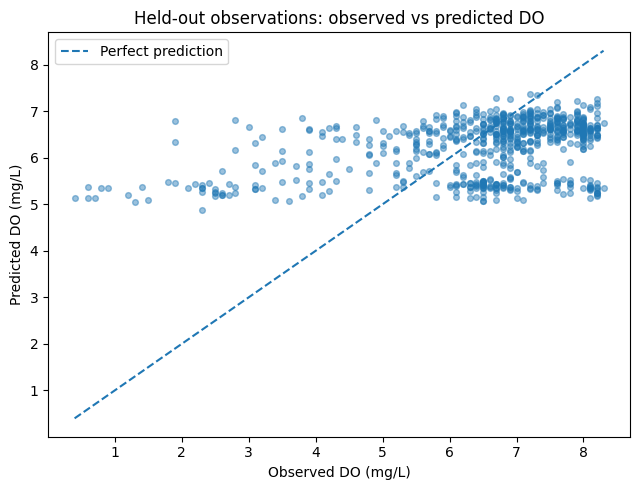

In [6]:
plt.figure(figsize=(6.5,5))
plt.scatter(out.do_mg_L,out.predicted_do_mg_L,alpha=.45,s=17)
lo=min(out.do_mg_L.min(),out.predicted_do_mg_L.min()); hi=max(out.do_mg_L.max(),out.predicted_do_mg_L.max())
plt.plot([lo,hi],[lo,hi],'--',label='Perfect prediction')
plt.xlabel('Observed DO (mg/L)'); plt.ylabel('Predicted DO (mg/L)'); plt.title('Held-out observations: observed vs predicted DO'); plt.legend(); plt.tight_layout(); plt.savefig('observed_vs_predicted.png',dpi=160); plt.show()

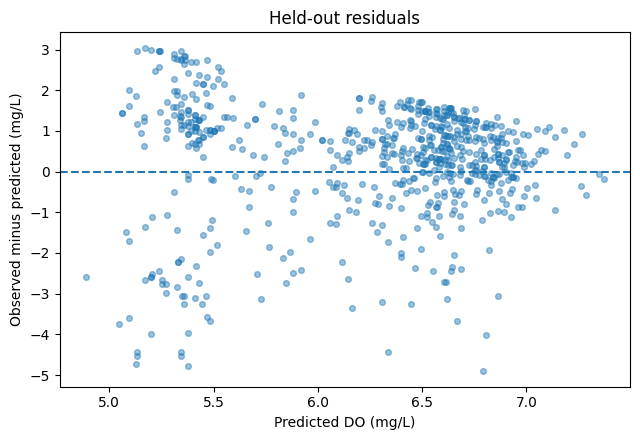

In [7]:
plt.figure(figsize=(6.5,4.5))
plt.scatter(out.predicted_do_mg_L,out.residual_actual_minus_predicted,alpha=.45,s=17)
plt.axhline(0,linestyle='--'); plt.xlabel('Predicted DO (mg/L)'); plt.ylabel('Observed minus predicted (mg/L)'); plt.title('Held-out residuals'); plt.tight_layout(); plt.savefig('residuals.png',dpi=160); plt.show()

## 4. Interpretation

I used multiple linear regression to estimate dissolved oxygen (DO) from pH, district, and seasonal timing in Kerala (Central Pollution Control Board, n.d.). The model was trained on 2,670 observations and tested on 671 later observations. Its test R² was 0.126, with RMSE of 1.44 mg/L and MAE of 1.13 mg/L, indicating limited predictive ability despite outperforming the mean baseline (Scikit-learn, n.d.-b). For the 37 test readings below 3.05 mg/L, the average predicted DO was 5.46 mg/L, suggesting the model could overlook unusually low oxygen conditions. Uneven station coverage, missing BOD measurements, and the linear model’s assumptions limit the results. I would use this model for preliminary estimates, not pollution warnings, and collect additional measurements before relying on its predictions.

## References
Central Pollution Control Board. (n.d.). *Surface water quality: Manual chemical parameters (CPCB)* [Data set]. National Water Data Portal. https://nwdp.nwic.gov.in/dataset/surface-water-quality-manual-chemical-parameters-cpcb/resource/744b2bd4-7483-4eb1-a59a-5fbe06b62588

Scikit-learn. (n.d.-a). *Getting started*. https://scikit-learn.org/stable/getting_started.html

Scikit-learn. (n.d.-b). *Metrics and scoring: Quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html